# 01 · Cleaning: from the raw CBS export to one row per neighbourhood

**Story:** helping an international newcomer find neighbourhoods with relatively lower housing values,
within reach of the city where they work.

**This notebook** turns two raw sources into the table the story is built on:

| Source | What | Licence |
|---|---|---|
| CBS *Kerncijfers wijken en buurten 2025* (table **86165NED**) | statistics per neighbourhood (buurt) | CC-BY 4.0 |
| CBS / Kadaster *Wijk- en buurtkaart 2025 v1* | neighbourhood boundaries (GeoPackage) | CC-BY 4.0, credit CBS and Kadaster |

It repeats the decisions from the scripts in `src/` (kept there as the record of how I got here) and adds
three things the story needed: the split between corporation and private rentals, the neighbourhood map,
and an explicit text-to-number step.

Run it with **Kernel → Restart & Run All**. Raw files are expected in `data/raw/` and `data/geo/`
(see the README for the download commands).

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# the notebook lives in notebooks/, the data one level up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
GEO = ROOT / "data" / "geo" / "WijkBuurtkaart_2025_v1" / "wijkenbuurten_2025_v1.gpkg"
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

print("pandas", pd.__version__, "| geopandas", gpd.__version__)
print("raw files:", sorted(p.name for p in RAW.glob("*.csv")))
print("map found:", GEO.exists())

pandas 3.0.5 | geopandas 1.2.0
raw files: ['86165NED.csv', 'Catalog.csv', 'Dimensions.csv', 'Distribution.csv', 'LinkProvenances.csv', 'LinkRelatedSources.csv', 'MeasureCodes.csv', 'MeasureGroups.csv', 'Observations.csv', 'Properties.csv', 'WijkenEnBuurtenCodes.csv', 'WijkenEnBuurtenGroups.csv']
map found: True


## 1 · Load the raw observations

The CBS export is *long* (one row per region × measure), not one row per neighbourhood.
I read every column as text first and convert on purpose later: in my environment pandas reads
the `Value` column as text, so a silent conversion would hide problems.

In [2]:
obs = pd.read_csv(RAW / "Observations.csv", sep=";", encoding="utf-8", dtype=str)
obs["WijkenEnBuurten"] = obs["WijkenEnBuurten"].str.strip()
print("shape:", obs.shape)
print("distinct measures:", obs["Measure"].nunique())
obs.head()

shape: (1596799, 6)
distinct measures: 90


,Id,Measure,WijkenEnBuurten,Value,StringValue,ValueAttribute
0,0,GM000C,NL00,NaN,Nederland,NaN
1,1,R00003,NL00,NaN,Land,NaN
2,2,R00004,NL00,NaN,NL00,NaN
3,3,T001036,NL00,18044027,NaN,NaN
4,4,3000,NL00,8978451,NaN,NaN


## 2 · Pick the measures

18 numeric measures from the original project, plus two new ones for the story.
`pct_rental` alone mixes social housing (long waiting lists, not realistic for a newcomer) with private rentals,
so I split it:

* `A047047` *In bezit woningcorporatie* → `pct_rent_corporation`
* `A047048` *In bezit overige verhuurders* → `pct_rent_private`

In [3]:
NUMERIC_MEASURES = {
    "T001036": "population",
    "M000100": "population_density",
    "M000297": "dwelling_count",
    "M001642": "avg_woz_value_k_eur",
    "ZW10290": "pct_single_family",
    "ZW10340": "pct_multi_family",
    "1014800": "pct_owner_occupied",
    "1014850_2": "pct_rental",
    "A047047": "pct_rent_corporation",   # new for the story
    "A047048": "pct_rent_private",       # new for the story
    "M008209": "pct_built_over_10y_ago",
    "M008210": "pct_built_last_10y",
    "D000028": "dist_gp_km",
    "D000025": "dist_supermarket_km",
    "D000029": "dist_daycare_km",
    "D000045": "dist_school_km",
    "D000263": "schools_within_3km",
    "M000222": "avg_standardized_income_k_eur",
    "ST0001": "urbanity_level",
    "ST0003": "address_density",
}
STRING_MEASURES = {
    "GM000C": "municipality",
    "R00003": "region_type",
    "R00004": "region_code",
    "PC000C": "postcode",
}

present = set(obs["Measure"].unique())
for code_, name in NUMERIC_MEASURES.items():
    if code_ not in present:
        print(f"NOT IN THIS RELEASE: {code_} ({name})")

NOT IN THIS RELEASE: M000222 (avg_standardized_income_k_eur)


## 3 · Text → number, then long → wide

CBS writes decimals with a **comma** (`1,2` km), the Dutch way. `pd.to_numeric` only understands a point,
and with `errors="coerce"` it turns `1,2` into NaN **without any warning**.

That is exactly what happened in my first pipeline (`src/07_handling_missing_revised.py`): the distance
measures, the only measures with decimals, looked 72–94 % empty, and I concluded CBS had not published them.
The cell below shows the two ways side by side, so the mistake and the fix are both on the record.

In [4]:
num = obs[obs["Measure"].isin(NUMERIC_MEASURES)].copy()
raw_text = num["Value"].str.strip()

old_way = pd.to_numeric(raw_text, errors="coerce")                                   # src/07
new_way = pd.to_numeric(raw_text.str.replace(",", ".", regex=False), errors="coerce")  # this notebook

has_comma = raw_text.str.contains(",", na=False)
comparison = pd.DataFrame({
    "values with a comma": has_comma.groupby(num["Measure"]).sum(),
    "missing % old way": old_way.isna().groupby(num["Measure"]).mean().mul(100).round(1),
    "missing % new way": new_way.isna().groupby(num["Measure"]).mean().mul(100).round(1),
}).rename(index=NUMERIC_MEASURES)
comparison[comparison["values with a comma"] > 0]

,values with a comma,missing % old way,missing % new way
Measure,,,
dist_supermarket_km,16251,91.9,0.0
dist_gp_km,16174,91.5,0.0
dist_daycare_km,16596,93.9,0.0
dist_school_km,16410,92.8,0.0
schools_within_3km,12681,71.7,0.0


Only the measures in this table contain commas, so every other column from the first project is unaffected.
From here on the comma-safe conversion is used, and anything that still is not a number is counted.

In [5]:
num["Value"] = new_way

not_a_number = raw_text.notna() & (raw_text != "") & num["Value"].isna()
print("values present but not numeric:", int(not_a_number.sum()))
if not_a_number.any():
    print(num.loc[not_a_number, "Measure"].value_counts().head(10))
    print("examples:", raw_text[not_a_number].unique()[:10])

numeric_wide = (num.pivot_table(index="WijkenEnBuurten", columns="Measure",
                                values="Value", aggfunc="first")
                   .rename(columns=NUMERIC_MEASURES))

txt = obs[obs["Measure"].isin(STRING_MEASURES)]
string_wide = (txt.pivot_table(index="WijkenEnBuurten", columns="Measure",
                               values="StringValue", aggfunc="first")
                  .rename(columns=STRING_MEASURES))
for col in string_wide.columns:
    string_wide[col] = string_wide[col].str.strip()   # CBS pads text with spaces

names = pd.read_csv(RAW / "WijkenEnBuurtenCodes.csv", sep=";", encoding="utf-8", dtype=str)
names = names.rename(columns={"Identifier": "WijkenEnBuurten", "Title": "region_name"})
names["WijkenEnBuurten"] = names["WijkenEnBuurten"].str.strip()

wide = (string_wide.join(numeric_wide).reset_index()
        .merge(names[["WijkenEnBuurten", "region_name"]], on="WijkenEnBuurten", how="left"))
print("wide table:", wide.shape)
wide["region_type"].value_counts()

values present but not numeric: 0


wide table: (18495, 25)


region_type
Buurt       14729
Wijk         3423
Gemeente      342
Land            1
Name: count, dtype: int64

## 4 · Keep neighbourhoods only

The wide table mixes country, municipalities, districts and neighbourhoods. Keeping the higher levels
would count the same people twice, so only `Buurt` rows stay.

In [6]:
df = wide[wide["region_type"] == "Buurt"].copy()
print("neighbourhoods:", len(df))

if (df["region_code"] == df["WijkenEnBuurten"]).all():
    df = df.drop(columns="region_code")
    print("region_code duplicates WijkenEnBuurten -> dropped")

neighbourhoods: 14729
region_code duplicates WijkenEnBuurten -> dropped


## 5 · Missing values: three tiers

Same rule as `src/07_handling_missing_revised.py`:

1. **more than 40 % missing → drop the column.** In the first project this rule removed the five
   distance-to-amenity measures. With the comma fixed (section 3) they are about 5 % missing at
   neighbourhood level, so the rule no longer removes them, and they fall under tier 2 instead.
   The rule itself stays: it is still the right decision for a column that really is mostly empty.
2. **under 25 % missing → fill with the median of the same municipality**, because housing differs far more
   between municipalities than within one. Every filled value is listed in `imputed_fields`.
3. **rows still missing a core field → drop.**

In [7]:
numeric_cols = [c for c in NUMERIC_MEASURES.values() if c in df.columns]
missing_pct = (df[numeric_cols].isna().mean() * 100).sort_values(ascending=False).round(1)
missing_pct.to_frame("missing %")

,missing %
avg_woz_value_k_eur,12.5
pct_owner_occupied,11.5
pct_rent_corporation,11.5
pct_rent_private,11.5
pct_rental,11.5
pct_multi_family,11.5
pct_single_family,11.5
pct_built_last_10y,11.5
pct_built_over_10y_ago,11.5
dist_supermarket_km,5.3


The three ownership columns (`pct_rental`, `pct_rent_corporation`, `pct_rent_private`) are missing in
**exactly the same** neighbourhoods. CBS leaves the whole ownership block out for some neighbourhoods,
most likely very small ones, rather than publishing a figure about a handful of homes.

In [8]:
own = ["pct_rental", "pct_rent_corporation", "pct_rent_private"]
own = [c for c in own if c in df.columns]
n_missing = df[own].isna().sum(axis=1)
print("ownership block missing together in every case:", n_missing.isin([0, len(own)]).all())
print("neighbourhoods without ownership figures:", int((n_missing == len(own)).sum()))
print("their median population:", df.loc[n_missing == len(own), "population"].median(),
      "| others:", df.loc[n_missing == 0, "population"].median())

ownership block missing together in every case: True
neighbourhoods without ownership figures: 1692
their median population: 15.0 | others: 905.0


In [9]:
# tier 1: drop columns that are mostly empty
drop_cols = missing_pct[missing_pct > 40].index.tolist()
print("dropped (>40% missing):", drop_cols)
df = df.drop(columns=drop_cols)
remaining = [c for c in numeric_cols if c not in drop_cols]

# tier 2: municipality median for columns under 25% missing
df["imputed_fields"] = ""
for col in remaining:
    share = df[col].isna().mean()
    if 0 < share < 0.25:
        was_missing = df[col].isna()
        df[col] = df.groupby("municipality")[col].transform(lambda s: s.fillna(s.median()))
        df[col] = df[col].fillna(df[col].median())   # municipality with no values at all
        df.loc[was_missing, "imputed_fields"] += col + ";"
        print(f"filled {col}: {share:.1%} missing")
df["imputed_fields"] = df["imputed_fields"].str.rstrip(";")

# tier 3: rows still missing a core field
core = ["avg_woz_value_k_eur", "dwelling_count", "population"]
before = len(df)
df = df.dropna(subset=core)
print("rows dropped for missing core fields:", before - len(df))
print("neighbourhoods with at least one estimated value:", int((df["imputed_fields"] != "").sum()))

dropped (>40% missing): []


filled population_density: 5.2% missing
filled avg_woz_value_k_eur: 12.5% missing
filled pct_single_family: 11.5% missing


filled pct_multi_family: 11.5% missing
filled pct_owner_occupied: 11.5% missing
filled pct_rental: 11.5% missing


filled pct_rent_corporation: 11.5% missing
filled pct_rent_private: 11.5% missing
filled pct_built_over_10y_ago: 11.5% missing


filled pct_built_last_10y: 11.5% missing
filled dist_gp_km: 5.3% missing
filled dist_supermarket_km: 5.3% missing


filled dist_daycare_km: 5.3% missing
filled dist_school_km: 5.3% missing
filled schools_within_3km: 5.3% missing
filled urbanity_level: 0.6% missing


filled address_density: 0.6% missing
rows dropped for missing core fields: 0
neighbourhoods with at least one estimated value: 1842


## 6 · Sanity check: do the two rental shares add up?

Corporation + private should equal total rentals. A difference of ±1 is rounding, because CBS publishes
whole percentages. For *estimated* neighbourhoods the three columns were filled independently,
so they do not have to add up there; that is one more reason the app marks them as estimates.

In [10]:
measured = df["imputed_fields"] == ""
gap = (df["pct_rent_corporation"] + df["pct_rent_private"] - df["pct_rental"])
print("measured neighbourhoods, gap distribution:")
print(gap[measured].describe().round(2))
print("share with |gap| <= 1:", round((gap[measured].abs() <= 1).mean(), 4))

measured neighbourhoods, gap distribution:
count    12887.00
mean        -0.00
std          0.41
min         -1.00
25%          0.00
50%          0.00
75%          0.00
max          1.00
dtype: float64
share with |gap| <= 1: 1.0


## 7 · Outliers: flag and keep

IQR rule (1.5 × IQR) on the unbounded columns. A canal-house neighbourhood in Amsterdam or an almost empty
polder neighbourhood is real, so nothing is removed. Capped copies go into `*_capped` columns for
statistics that react badly to extremes; the original columns are never overwritten.

In [11]:
KEY = ["avg_woz_value_k_eur", "dwelling_count", "population", "population_density", "address_density"]
KEY = [c for c in KEY if c in df.columns]

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

rows = []
for col in KEY:
    lo, hi = iqr_bounds(df[col].dropna())
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    rows.append({"column": col, "lower": round(lo, 1), "upper": round(hi, 1),
                 "outliers": n_out, "share %": round(100 * n_out / len(df), 1)})
    df[f"{col}_capped"] = df[col].clip(lo, hi)
pd.DataFrame(rows)

,column,lower,upper,outliers,share %
0,avg_woz_value_k_eur,68.5,784.5,527,3.6
1,dwelling_count,-985.5,1834.5,840,5.7
2,population,-2067.5,3952.5,800,5.4
3,population_density,-7572.0,13036.0,369,2.5
4,address_density,-2188.5,4151.5,643,4.4


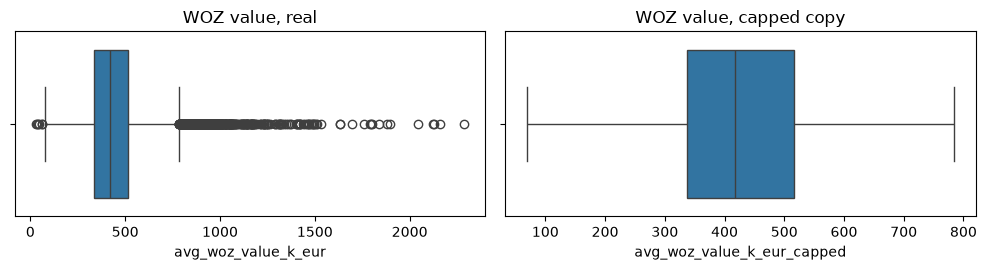

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
sns.boxplot(x=df["avg_woz_value_k_eur"], ax=axes[0]).set_title("WOZ value, real")
sns.boxplot(x=df["avg_woz_value_k_eur_capped"], ax=axes[1]).set_title("WOZ value, capped copy")
plt.tight_layout()
plt.show()

## 8 · Join the map

The map has every neighbourhood plus a few that are not places where people live: open water
(`water = JA`) and one code for "abroad". Those have no statistics and are left out. Every neighbourhood
in my table must find its shape; the cell stops if one does not.

In [13]:
geo = gpd.read_file(GEO, layer="buurten", columns=["buurtcode", "water"])
geo["buurtcode"] = geo["buurtcode"].str.strip()
print("map CRS:", geo.crs, "| shapes:", len(geo))

in_map_only = geo[~geo["buurtcode"].isin(df["WijkenEnBuurten"])]
in_table_only = set(df["WijkenEnBuurten"]) - set(geo["buurtcode"])
print("in the map but not in my table:", len(in_map_only))
print(in_map_only["water"].value_counts())
assert not in_table_only, f"{len(in_table_only)} neighbourhoods have no shape"

map CRS: EPSG:28992 | shapes: 14823
in the map but not in my table: 94
water
JA    93
B      1
Name: count, dtype: int64


The map is in **RD New (EPSG:28992)**, the Dutch grid in metres. I keep each neighbourhood's centre point
in metres so distances later are plain Pythagoras, no latitude/longitude maths.
For the app I also save a simplified copy of the shapes in latitude/longitude (what web maps expect).
Simplifying by 50 m makes the file much smaller; at neighbourhood scale it is not visible.

In [14]:
shapes = geo[geo["buurtcode"].isin(df["WijkenEnBuurten"])][["buurtcode", "geometry"]]
centres = shapes.geometry.representative_point()   # always inside the shape, unlike a plain centroid
df = df.merge(pd.DataFrame({"WijkenEnBuurten": shapes["buurtcode"],
                            "x_rd": centres.x.round(0), "y_rd": centres.y.round(0),
                            "area_km2": (shapes.area / 1e6).round(3)}),
              on="WijkenEnBuurten", how="left")

light = shapes.copy()
light["geometry"] = light.geometry.simplify(50, preserve_topology=True)
light = light.to_crs(4326)
geojson_path = OUT / "buurten_simplified.geojson"
light.to_file(geojson_path, driver="GeoJSON", COORDINATE_PRECISION=5)
print("geojson:", geojson_path.name, round(geojson_path.stat().st_size / 1e6, 1), "MB")

geojson: buurten_simplified.geojson 7.4 MB


## 9 · Save

`postcode` is an identifier, not a number (`9712.0` → `"9712"`).

In [15]:
df["postcode"] = pd.to_numeric(df["postcode"], errors="coerce").astype("Int64").astype("string")
csv_path = OUT / "buurten_story.csv"
df.to_csv(csv_path, index=False)
print("saved", csv_path.name, df.shape)
df.head()

saved buurten_story.csv (14729, 33)


,WijkenEnBuurten,municipality,postcode,region_type,pct_owner_occupied,pct_rental,pct_rent_corporation,pct_rent_private,dist_supermarket_km,dist_gp_km,...,region_name,imputed_fields,avg_woz_value_k_eur_capped,dwelling_count_capped,population_capped,population_density_capped,address_density_capped,x_rd,y_rd,area_km2
0,BU00140000,Groningen,9712,Buurt,13.0,87.0,18.0,69.0,0.3,0.4,...,Binnenstad-Noord,,298.0,1834.5,3952.5,12845.0,4151.5,233656.0,582071.0,0.391
1,BU00140001,Groningen,9711,Buurt,12.0,87.0,24.0,63.0,0.3,0.3,...,Binnenstad-Zuid,,275.0,1834.5,3952.5,12855.0,4151.5,233864.0,581623.0,0.591
2,BU00140002,Groningen,9711,Buurt,12.0,88.0,31.0,57.0,0.5,0.5,...,Binnenstad-Oost,,253.0,1834.5,3952.5,13036.0,4151.5,234356.0,582083.0,0.289
3,BU00140003,Groningen,9718,Buurt,13.0,87.0,16.0,70.0,0.3,0.6,...,Binnenstad-West,,286.0,1069.0,1705.0,13036.0,4151.5,233223.0,581704.0,0.108
4,BU00140004,Groningen,9717,Buurt,70.0,30.0,10.0,16.0,0.5,0.5,...,Noorderplantsoen,avg_woz_value_k_eur;pct_single_family;pct_mult...,358.0,0.0,10.0,52.0,4151.5,232970.0,582491.0,0.196


## 10 · What changed, in numbers

This table is generated, so the cleaning log in `docs/appendix/` can quote it and stay true.

In [16]:
summary = pd.Series({
    "raw observations": len(obs),
    "neighbourhoods (Buurt)": len(df),
    "columns dropped (>40% missing)": len(drop_cols),
    "values with a decimal comma (lost in src/07)": int(has_comma.sum()),
    "values present but not numeric": int(not_a_number.sum()),
    "neighbourhoods with an estimated value": int((df["imputed_fields"] != "").sum()),
    "neighbourhoods without ownership figures (filled)": int(df["imputed_fields"].str.contains("pct_rental").sum()),
    "map shapes not used (water / abroad)": len(in_map_only),
    "total population": int(df["population"].sum()),
})
summary.to_frame("value")

,value
raw observations,1596799
neighbourhoods (Buurt),14729
columns dropped (>40% missing),0
values with a decimal comma (lost in src/07),78112
values present but not numeric,0
neighbourhoods with an estimated value,1842
neighbourhoods without ownership figures (filled),1692
map shapes not used (water / abroad),94
total population,18044120
